# Data Preprocessing

In [2]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

In [3]:
pip install scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
import numpy as np
import tensorflow as tf
import sklearn
# from tensorflow.keras.layers import Input, Layer, Dense, Add, Embedding  # <<<<============ Add Embegging here
# from tensorflow.keras.layers import Activation, Flatten
# from tensorflow.keras import optimizers
# from nltk.util import ngrams

I0000 00:00:1791883893.853985   61301 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791883896.748959   61301 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [5]:
from tensorflow.keras.layers import Input, Layer, Dense
from tensorflow.keras.models import Model
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

In [6]:
import pickle
import nltk
from nltk.corpus import gutenberg
from tensorflow.keras.preprocessing.text import Tokenizer

# 1. Download Gutenberg dataset and sentence tokenizer
nltk.download('gutenberg')
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package gutenberg to
[nltk_data]     /home/codespace/nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!
[nltk_data] Downloading package punkt to /home/codespace/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/codespace/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [19]:
# 2. Extract sentences 
raw_sentences = gutenberg.sents()[:8000]

# Join tokens back into clean lowercase strings
sentences = [" ".join(s).lower() for s in raw_sentences if len(s) > 4]

# 3. Fit Tokenizer to build vocabulary and sequences
VOCAB_SIZE = 3000
tokenizer = Tokenizer(num_words=VOCAB_SIZE)
tokenizer.fit_on_texts(sentences)

word2idx = {k: v for k, v in tokenizer.word_index.items() if v <= VOCAB_SIZE}
idx2word = {v: k for k, v in word2idx.items()}

sequences = tokenizer.texts_to_sequences(sentences)
# Filter out empty or very short sequences after filtering
sequences = [seq for seq in sequences if len(seq) >= 5]

# 4. Save to data/gutenberg.pkl
os.makedirs('data', exist_ok=True)
with open('data/gutenberg.pkl', 'wb') as f:
    pickle.dump((word2idx, idx2word, sequences), f)

print(f"Saved! Vocab size: {len(word2idx)}, Total sentences: {len(sequences)}")

Saved! Vocab size: 3000, Total sentences: 7053


In [20]:
# create training dataset with 5-grams
n_grams = 5
x_train = []
y_train = []
for sequence in sequences:
    if len(sequence) >= n_grams:
        for a, b, c, d, e in nltk.ngrams(sequence, n_grams):   # c is the center word. d, e are the context words
            x_train.append([a,b,d,e])
            y_train.append(c)


x_train = np.array(x_train)
y_train = np.array(y_train).reshape(-1,1)

n_vocab = len(word2idx) # vocab size
n_emb = 32 #word emb vector size

In [22]:
sequences

[[34,
  93,
  440,
  633,
  3,
  916,
  23,
  5,
  528,
  161,
  3,
  177,
  716,
  155,
  2,
  2837,
  100,
  4,
  1,
  243,
  1729,
  4,
  1591,
  3,
  17,
  614,
  1049,
  562,
  63,
  285,
  11,
  1,
  248,
  23,
  24,
  77,
  2,
  817,
  55,
  8],
 [10,
  9,
  1,
  2104,
  4,
  1,
  131,
  1465,
  4,
  5,
  103,
  1466,
  113,
  3,
  17,
  11,
  542,
  4,
  8,
  499,
  27,
  30,
  490,
  35,
  1177,
  4,
  25,
  193,
  51,
  5,
  24,
  449,
  849],
 [8,
  267,
  17,
  1890,
  104,
  152,
  548,
  20,
  8,
  2,
  21,
  60,
  68,
  61,
  1368,
  4,
  8,
  3,
  8,
  213,
  17,
  35,
  2105,
  44,
  61,
  500,
  163,
  18,
  1467,
  90,
  17,
  1730,
  77,
  281,
  4,
  5,
  267,
  11,
  389],
 [1260,
  285,
  17,
  46,
  413,
  35,
  11,
  26,
  93,
  27,
  30,
  234,
  289,
  18,
  5,
  1467,
  68,
  5,
  134,
  24,
  468,
  4,
  244,
  1465,
  19,
  414,
  4,
  34],
 [273, 65, 7, 9, 60, 1, 765, 4, 1106],
 [164,
  106,
  46,
  413,
  17,
  1731,
  2,
  959,
  1,
  917,
  4,
  1467,


In [23]:
len(sequences)

7053

In [24]:
print(f"no. of unique words: {len(word2idx)}")
word2idx

no. of unique words: 3000


{'the': 1,
 'to': 2,
 'and': 3,
 'of': 4,
 'a': 5,
 'i': 6,
 'it': 7,
 'her': 8,
 'was': 9,
 'she': 10,
 'in': 11,
 'not': 12,
 'be': 13,
 'you': 14,
 'he': 15,
 'that': 16,
 'had': 17,
 'as': 18,
 'but': 19,
 'for': 20,
 'have': 21,
 'is': 22,
 'with': 23,
 'very': 24,
 'his': 25,
 'mr': 26,
 "'": 27,
 'at': 28,
 'so': 29,
 's': 30,
 'all': 31,
 'could': 32,
 'would': 33,
 'emma': 34,
 'been': 35,
 'him': 36,
 'no': 37,
 'my': 38,
 'on': 39,
 'mrs': 40,
 'any': 41,
 'do': 42,
 'were': 43,
 'by': 44,
 'which': 45,
 'miss': 46,
 'must': 47,
 'will': 48,
 'me': 49,
 'there': 50,
 'from': 51,
 'they': 52,
 'what': 53,
 'this': 54,
 'or': 55,
 'much': 56,
 'harriet': 57,
 'such': 58,
 'if': 59,
 'more': 60,
 'an': 61,
 'said': 62,
 'one': 63,
 'are': 64,
 'them': 65,
 'every': 66,
 'weston': 67,
 'than': 68,
 'am': 69,
 'well': 70,
 'thing': 71,
 'think': 72,
 'should': 73,
 'being': 74,
 'knightley': 75,
 'elton': 76,
 'little': 77,
 'never': 78,
 'your': 79,
 'how': 80,
 'when': 81,
 'go

In [25]:
idx2word

{1: 'the',
 2: 'to',
 3: 'and',
 4: 'of',
 5: 'a',
 6: 'i',
 7: 'it',
 8: 'her',
 9: 'was',
 10: 'she',
 11: 'in',
 12: 'not',
 13: 'be',
 14: 'you',
 15: 'he',
 16: 'that',
 17: 'had',
 18: 'as',
 19: 'but',
 20: 'for',
 21: 'have',
 22: 'is',
 23: 'with',
 24: 'very',
 25: 'his',
 26: 'mr',
 27: "'",
 28: 'at',
 29: 'so',
 30: 's',
 31: 'all',
 32: 'could',
 33: 'would',
 34: 'emma',
 35: 'been',
 36: 'him',
 37: 'no',
 38: 'my',
 39: 'on',
 40: 'mrs',
 41: 'any',
 42: 'do',
 43: 'were',
 44: 'by',
 45: 'which',
 46: 'miss',
 47: 'must',
 48: 'will',
 49: 'me',
 50: 'there',
 51: 'from',
 52: 'they',
 53: 'what',
 54: 'this',
 55: 'or',
 56: 'much',
 57: 'harriet',
 58: 'such',
 59: 'if',
 60: 'more',
 61: 'an',
 62: 'said',
 63: 'one',
 64: 'are',
 65: 'them',
 66: 'every',
 67: 'weston',
 68: 'than',
 69: 'am',
 70: 'well',
 71: 'thing',
 72: 'think',
 73: 'should',
 74: 'being',
 75: 'knightley',
 76: 'elton',
 77: 'little',
 78: 'never',
 79: 'your',
 80: 'how',
 81: 'when',
 82:

In [26]:
x_train[:5]

array([[ 34,  93, 633,   3],
       [ 93, 440,   3, 916],
       [440, 633, 916,  23],
       [633,   3,  23,   5],
       [  3, 916,   5, 528]])

In [27]:
y_train[:5]

array([[440],
       [633],
       [  3],
       [916],
       [ 23]])

# CBOW Embedding Model

In [28]:
# word embedding layer
class WordEmbedding(Layer):
    def __init__(self, input_dim, emb_size, name=None):
        super(WordEmbedding, self).__init__(name=name)

        # Matrix C registered as a Keras layer weight
        self.C = self.add_weight(
            name='C',
            shape=(input_dim, emb_size),
            initializer='random_normal',
            trainable=True
        )

    def call(self, x):
        # Table look up in C
        selected_rows = tf.gather(self.C, x) # (None, 3, 8)
        return selected_rows
        

In [29]:
x_input = Input(batch_shape = (None, x_train.shape[1]), dtype='int32')
x_emb = WordEmbedding(n_vocab, n_emb, name='emb')(x_input) 
x_avg = tf.keras.layers.GlobalAveragePooling1D()(x_emb)
y_output = Dense(n_vocab, activation='softmax')(x_avg)  

In [31]:
# CBOW model
model = Model(x_input, y_output)
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam'
)
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 4)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ emb (WordEmbedding)             │ (None, 4, 32)          │        96,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3000)           │        99,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 195,000 (761.72 KB)

 Trainable params: 195,000 (761.72 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
# fit data to the model
hist = model.fit(x_train, y_train, batch_size=256, shuffle=True, epochs=20)

Epoch 1/20
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - loss: 6.6274
Epoch 2/20
522/522 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - loss: 5.9817
Epoch 3/20
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 5.7799
Epoch 4/20
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - loss: 5.6207
Epoch 5/20
522/522 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - loss: 5.4908
Epoch 6/20
522/522 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - loss: 5.3712
Epoch 7/20
522/522 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 5.2613
Epoch 8/20
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 5.1644
Epoch 9/20
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 5.0801
Epoch 10/20
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 5.0067
Epoch 11/20
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 4.9424
Epoch 12/20
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 4.8851
Epoch 13/20
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 4.8333
Epoch 14/20
522/522 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 4.7861
Epoch 15/20
522/522 ━━━━━━━━━━━━━━━━━━━━ 

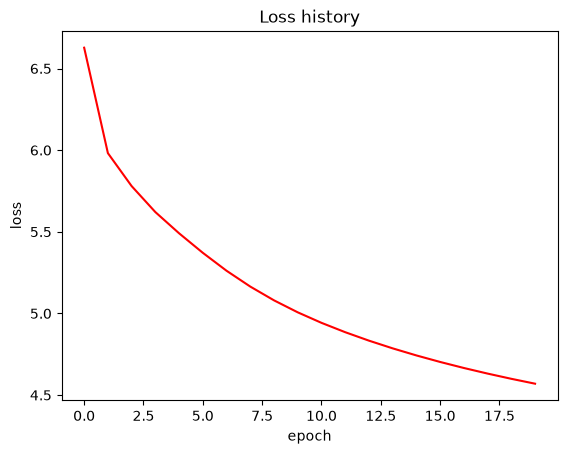

In [33]:
# losss history
plt.plot(hist.history['loss'], color='red')
plt.title("Loss history")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.show()

In [39]:
# word embedding matrix C
C = model.get_layer('emb').get_weights()[0]
print("Shape of C:", C.shape)

Shape of C: (3000, 32)


# Visialize the context Mapping of different words

In [50]:
# principal component analysis
# reduce 32-dim C matrix into a 2D vector space -> we use PCA
pca = PCA(n_components=2)
pca_C = pca.fit_transform(C)

In [ ]:
# we represent the two-dimensional embedding vectors of
# the following words in a two-dimensional space.
words = [
    # 1. Family / Relatives
     'father', 'daughter', 'sister', 

    # 3. Emotions / Internal States
    'happiness', 'pleasure', 'pride',

    # # 5. Time Units
    'evening', 'hour', 
]
words_idx = np.array([word2idx[x] for x in words])
words_vec = pca_C[words_idx]

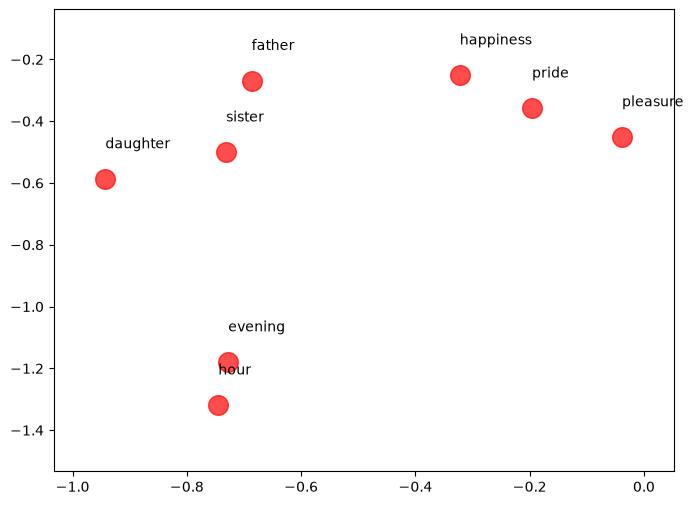

In [110]:
x = words_vec[:, 0]
y = words_vec[:, 1]
plt.figure(figsize=(8,6))
plt.scatter(x,y,s=200,c='red',alpha=0.7)
plt.margins(x=0.1, y=0.2)
for i in range(len(words)):
    plt.annotate(words[i], (x[i],y[i] + 0.1))
plt.show()